# 04 First order conduit stats

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from os.path import exists, split, join
from os import makedirs
from tqdm import tqdm
from matplotlib.gridspec import GridSpec
from scipy.stats import gaussian_kde
from stl import mesh
import base.geometry as geom

from base.utils import list_all_centrelines, return_centreline_parametrisation, list_all_plymeshes

C:\Users\tangr\AppData\Roaming\Python\Python310\site-packages\matplotlib\projections\__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# change here the path to the repository of karst catalogue
#data_repository = "F:/ScanLeica/data_paper/KarstConduitCatalogue" 
data_repository = "D:/KarstConduitCatalogue"
centreline_filepaths = list_all_centrelines(data_repository)

In [3]:
centreline_filepaths

['D:\\KarstConduitCatalogue\\Hoelloch\\KellerAquarium\\geometric_descriptors\\Hoelloch_KellerAquarium_centreline.txt',
 'D:\\KarstConduitCatalogue\\Hoelloch\\Riesengang\\geometric_descriptors\\Hoelloch_Riesengang_centreline.txt',
 'D:\\KarstConduitCatalogue\\Hoelloch\\Seengang\\geometric_descriptors\\Hoelloch_Seengang_centreline.txt',
 'D:\\KarstConduitCatalogue\\Lauiloch\\EntranceGallery\\geometric_descriptors\\Lauiloch_EntranceGallery_centreline.txt']

We now select a specific cave passage and read out the section information, including the geometric descriptors.

In [37]:
idx = 0
INSET_SIZE = 8

sections_directory = join(split(centreline_filepaths[idx])[0], "sections")
stub = len("_centreline.txt")
thecavepassage = split(centreline_filepaths[idx])[1][:-stub]

Now we can find and load the geometric descriptors calculated on the relevant sections. 

In [38]:
descriptors_filepath = join(split(centreline_filepaths[idx])[0], "section_descriptors.txt")
conduit_descriptors = np.loadtxt(descriptors_filepath, delimiter=" ", skiprows=1)
with open(descriptors_filepath, "r") as f:
    header = f.readline()[2:-1].split(",")
    f.close()

In [39]:
len(conduit_descriptors)

287

In [40]:

meshes_filepaths = list_all_plymeshes(data_repository)
meshdata = mesh.Mesh.from_file(meshes_filepaths[idx][:-3] + "stl")

Since we have twenty descriptors, we can have a look at all descriptors in a matrix of histograms. 

We let $\Omega$ be the section object, with an outer contour called $p$ after `doi.org/10.1021/acscatal.5b02628`

$A = card(x) \mid x \in \Omega$

$P = \sum_{x \in p}{V(x)}, \text{V local weighting function}$

$L = max\left\Vert x_1 - x_2 \right\Vert x_1 \in p, x_2 \in p, x1 \neq x_2$

$r_{min}  = min\left\Vert x - c \right\Vert \mid x \in p$

$r_{max}  = max\left\Vert x - c \right\Vert \mid x \in p$

$r_{ave} = \frac{1}{card(p)} \sum_{x \in p}{\left\Vert x - c \right\Vert} $

$D_{H} = \frac{4A}{P}$

$\gamma_1 = \frac{r_{min}}{r_{max}}$

$\gamma_2 = \frac{P^2}{A}$

$\gamma_c = \frac{P}{2 \sqrt{\pi A}}$

$\gamma_3 = \frac{r_{max} - r_{min}}{r_{max}}$

$\delta_{inscribed} = \frac{\pi r_{min}^2}{A}$

$\delta_{circumscribed} = \frac{\pi r_{max}^2}{A}$

$E = \frac{4}{\pi} \frac{A}{{r_{ave}}^2}$

$d_{iso} = \frac{4 \pi A}{p^2}$

$\gamma_M = \frac{4}{\pi} \frac{A}{L^2}$

$\sigma^2_{circ} = \frac{\sum_{x \in \Omega}{(\left \Vert x - c \right \Vert -r_{ave})^2}}{Ar_{ave}^2}$

$S = \frac{card(x_1)}{card(x_2)} \mid x_1 \in \Omega, x_2 \in \mathcal{C}(\Omega)$

In [41]:
from matplotlib.cm import tab20b

In [42]:

def equivalent_dh(dhi, li):
    # harmonic mean along the section 
    return np.sum(li)**(1/4) * np.sum(li *dhi**(-4))**(-1/4)

In [43]:
def plotDH(sections,  idx, ax):
    dh = 4* geom.compute_ngon_area(sections[idx]) / geom.compute_ngon_perimeter(sections[idx])
    xi = np.linspace(0, 2*np.pi, 100)
    print(f"plotting the dh for section {idx} at {dh:.2f}m")
    # upper semi-circle
    ax.fill(dh/2*np.cos(xi), dh/2*np.sin(xi), alpha = 0.66, color = "grey", edgecolor=None)
    return ax

def plotCHull(sections,  idx, ax):
    chull = geom.compute_convex_hull(sections[idx])
    ax.fill(*sections[idx][:,[0, 1]].T, zorder = -9, color = "white")

    ax.fill(*chull[:,[0, 1]].T, zorder = -10, color = "sienna", alpha = 0.5)
    return ax


def plotR(sections, idx, ax, method):
    cog = geom.centre_of_gravity(sections[idx])

    ther, thearg = method(sections[idx], cog)

    ax.plot(*np.vstack([cog,sections[idx][thearg]]).T, color = "k", lw = 1)
    ax.scatter(*cog, marker="o", s=20, color="white", edgecolor="k")

In [44]:
header

['area',
 'ellipse_aspect_ratio',
 'ellipse_rotation',
 'perimeter',
 'solidity',
 'hydraulic_diameter',
 'max_chord_length',
 'rmax',
 'rmin',
 'r_average',
 'circularity',
 'circularity2',
 'gravelius_compactness',
 'circularity3',
 'deviation_from_inscribed_disk',
 'deviation_from_circumscribed_disk',
 'elongation',
 'isoperimetric_deficiency',
 'morton_spreading_index',
 'circular_variance',
 'curvilinear_coord']

In [45]:
def plotDescriptor(sections, descriptors, header, col, ax, 
                   ax_hist, 
                   ax_inset1, 
                   ax_inset2, 
                   inset_size = 10, 
                   last = False,
                   withmap = False,
                   attr_n = 0):
    
    # coordinates for plotting in the insets
    descriptor = descriptors[:, col]
    xi = descriptors[:, -1]
    above_min_area = descriptors[:, 0] > 0.5
    is_closed = descriptors[:, -2]

    print(np.sum(is_closed.astype(bool)))

    within_99 = np.logical_and(descriptor > np.quantile(descriptor, 0.005), descriptor < np.quantile(descriptor, 0.995))
    closed_within_99 = np.logical_and(is_closed.astype(bool), within_99)
    is_ok = np.logical_and(closed_within_99, above_min_area)

    descriptor_ok = descriptor[is_ok]
    xi_ok = xi[is_ok]


    sections_ok = np.array(sections, dtype=object)[is_ok]
    # indices to integers. 


    # indices of max and min descriptor value 
    argmax_descriptor = np.argmax(descriptor_ok)
    argmin_descriptor = np.argmin(descriptor_ok)



    _min = min(descriptor_ok)
    _max = max(descriptor_ok)
    _range = _max - _min

    if withmap==False:
    
        # Plotting along the curviline
        ax.plot(xi_ok, descriptor_ok, 
                "-o", 
                markersize = 3, 
                lw=0.75,
                color = tab20b(4*attr_n+1))

        ax.scatter(xi_ok[argmax_descriptor], descriptor_ok[argmax_descriptor], 
                color = "white",  
                edgecolor = tab20b(4*attr_n), 
                zorder = 100, 
                s = 20, 
                marker = "D")
        
        ax.scatter(xi_ok[argmin_descriptor], descriptor_ok[argmin_descriptor], 
                color = "white", 
                edgecolor = tab20b(4*attr_n+3), 
                zorder = 100, 
                s = 20, 
                marker = "D")
        
        ax.set_ylim(_min -0.1*_range, _max +0.1*_range)
    

    # Plotting the histogram
    nbins = int(1+ np.log2(len(descriptor_ok))) # sturges rule.
    ax_hist.hist(descriptor_ok, density = True, 
                 orientation = "horizontal", 
                 bins = nbins, 
                 color =tab20b(4*attr_n+3))

    # Gaussian KDE of the dataset, plotted on top of histogram. 
    yi = np.linspace(_min - 0.1*_range, _max + 0.1*_range, 100)
    kde = gaussian_kde(descriptor_ok).evaluate(yi)
    ax_hist.plot(kde, yi, lw = 3.5,c  = "white", zorder = 2)
    ax_hist.plot(kde, yi, lw = 1.5,c  = tab20b((4*attr_n)), zorder = 3)

    # Plotting the insets
    ax_inset1.plot(*sections_ok[argmax_descriptor][:,[0, 1]].T,  color = tab20b(4*attr_n))
    themaxsection = sections_ok[argmax_descriptor]

    ax_inset1.set_title(f"section {argmax_descriptor}")



    ax_inset2.plot(*sections_ok[argmin_descriptor][:,[0, 1]].T, color = tab20b((4*attr_n+3)))
    ax_inset2.set_title(f"section {argmin_descriptor}")


    # if hydraulic diameter. 
    if (header[col] == "hydraulic_diameter") and withmap == False: 
        plotDH(sections_ok, argmax_descriptor, ax_inset1)
        plotDH(sections_ok, argmin_descriptor, ax_inset2)

        li = np.diff(xi_ok)

        equiv_dh = equivalent_dh(descriptor_ok[:-1], li)
        ax.axhline(equiv_dh, ls="--", label = "equivalent hydraulic diameter", color = "k")

        ax.legend()
        
    elif header[col] == "solidity":
        plotCHull(sections_ok, argmax_descriptor, ax_inset1)
        plotCHull(sections_ok, argmin_descriptor, ax_inset2)

    elif header[col] == "rmin":
        plotR(sections_ok, argmax_descriptor, ax_inset1, geom.compute_rmin)
        plotR(sections_ok, argmin_descriptor, ax_inset2, geom.compute_rmin)
    
    elif header[col] == "rmax":
        plotR(sections_ok, argmax_descriptor, ax_inset1, geom.compute_rmax)
        plotR(sections_ok, argmin_descriptor, ax_inset2, geom.compute_rmax)
   
    # make cosmetic ajustments to insets 
    for ax_inset in (ax_inset1, ax_inset2):
        ax_inset.set_aspect("equal")
        ax_inset.tick_params(top=True, right=True, left = False, bottom= False)
        ax_inset.xaxis.tick_top()
        ax_inset.yaxis.tick_right()
        ax_inset.yaxis.set_label_position("right")
        ax_inset.set_ylabel("z [m]")
        ax_inset.set_xlim(-inset_size, inset_size)
        ax_inset.set_ylim(-inset_size, inset_size)


        tick_pos = np.round(inset_size*2 /3)
        ax_inset.set_xticks([-tick_pos,0,tick_pos])
        ax_inset.set_yticks([-tick_pos,0,tick_pos])
    
    if withmap == False:
        ax.grid(lw = 0.5, ls="--")

        for spine in ["top","right"]:
            ax.spines[spine].set_visible(False)
            ax_hist.spines[spine].set_visible(False)
    else:
        for spine in ["top","right"]:
            ax_hist.spines[spine].set_visible(False)


    # annotate with some interesting trivia
    if last == True:
        ax.set_xlabel("Coordinate along centreline [m]")

In [46]:
centreline_filepaths = list_all_centrelines(data_repository)
centreline_filepath = centreline_filepaths[idx]
assert exists(centreline_filepath)
centreline = np.loadtxt(centreline_filepath, skiprows=1)

In [47]:
interpolated_centreline, curvilinear_coords, normed_vectors = return_centreline_parametrisation(centreline, dt=0.5)

In [48]:
# too tortuous vectors, removed from calculation... 
ignore_calc = np.hstack(([False],  np.linalg.norm(np.diff(normed_vectors, axis=0), axis = 1) > 0.2))

In [49]:
np.savetxt(join(sections_directory, "ignore_flags.txt"), ignore_calc)

In [50]:
sections = [np.loadtxt(join(sections_directory, f"s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))]

In [51]:
sections2d = [geom.to2D(section, nP) for section, nP, remove in zip(sections, normed_vectors, ignore_calc) if not remove]

In [52]:
attributes = [0, 3, 5]
n_attr = len(attributes)

In [53]:
geom.is_closed(sections2d[0])

False

0
286
7
286
14
286
plotting the dh for section 279 at 3.90m
plotting the dh for section 102 at 2.18m


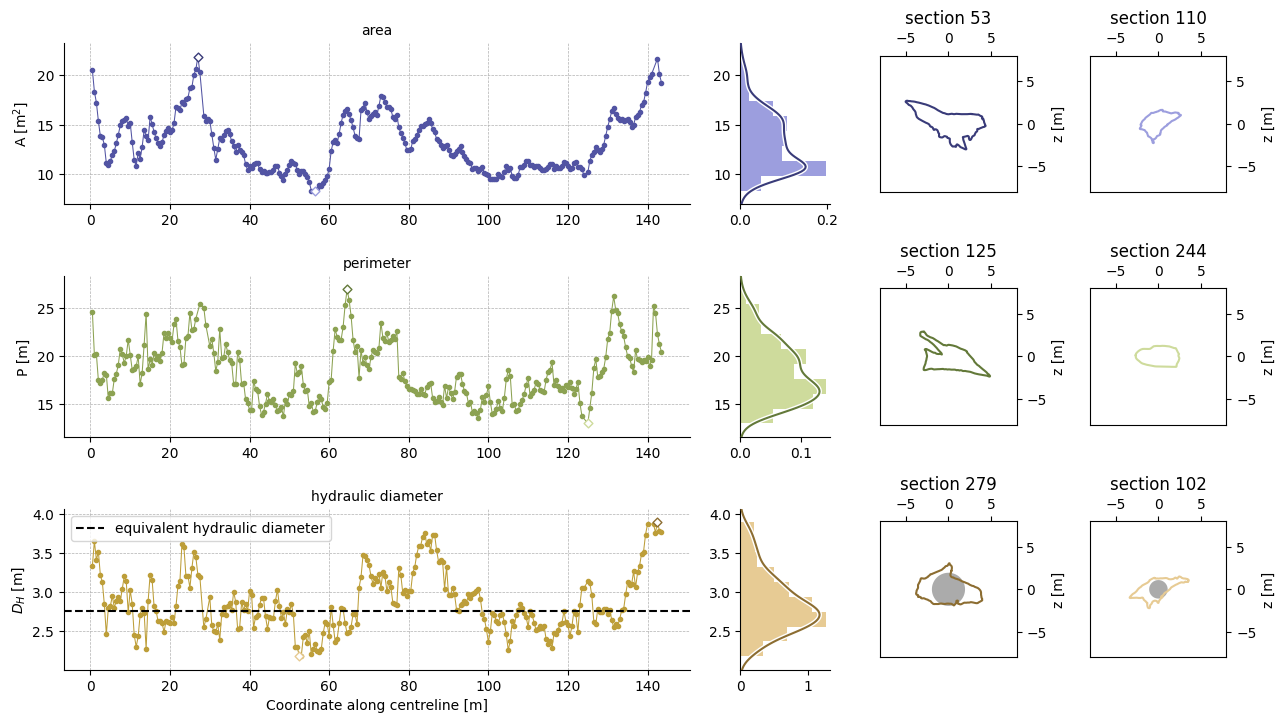

In [54]:
fig = plt.figure(figsize = (15, 3*n_attr))

gs = GridSpec(7*n_attr, 50)

labels = [geom.DESCRIPTOR_MAP[header[elem]]["name"] for elem in attributes]
units = [geom.DESCRIPTOR_MAP[header[elem]]["unit"] for elem in attributes]
abbrs = [geom.DESCRIPTOR_MAP[header[elem]]["abbr"] for elem in attributes]

descriptors = {}

for n, (col, label, unit, abbr) in enumerate(zip(attributes, labels, units, abbrs)):
    i = 7*n
    print(i)
    ax = fig.add_subplot(gs[i:i+5, :27])
    ax.set_ylabel(f"{abbr} [{unit}]")
    ax.set_title(label, fontsize =10)
    
    ax_hist = fig.add_subplot(gs[i:i+5, 29:33], sharey = ax)
    
    ax_inset1 = fig.add_subplot(gs[i:i+5, 35:41])
    ax_inset2 = fig.add_subplot(gs[i:i+5, 44:], sharex = ax_inset1, sharey = ax_inset1)
    
    last = False
    if n == len(attributes) -1:
        last = True

    
    plotDescriptor(sections2d, conduit_descriptors[~ignore_calc],header, col, ax, ax_hist, ax_inset1, ax_inset2, inset_size=INSET_SIZE, last = last, attr_n=n)

plt.savefig(f"./temp/barcelona_figures/curvilinear_attributes_{thecavepassage}_{'_'.join([str(elem) for elem in attributes])}.png")

0
286
7
286
14
286


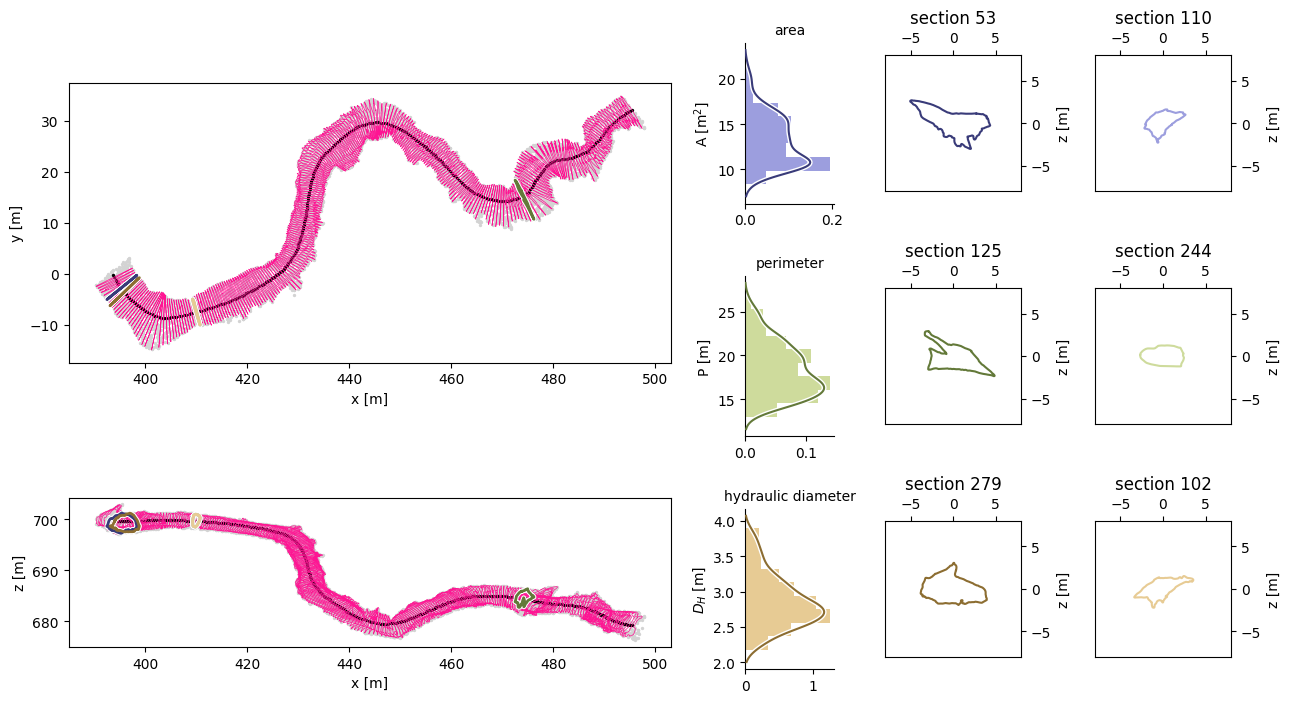

In [55]:
fig = plt.figure(figsize = (15, 3*n_attr))

gs = GridSpec(7*n_attr, 50)

# now we workout the ratio of yrange to zrange
_, yrange, zrange = np.max(meshdata.centroids, axis = 0) - np.min(meshdata.centroids, axis = 0)

frac_plan =int(0.9* np.floor(yrange / (yrange+zrange) * (7*n_attr)))

axmap_plan = fig.add_subplot(gs[:frac_plan, :26])
axmap_elev = fig.add_subplot(gs[frac_plan+1:-1, :26])

for axmap, secondcoord, ylabel in zip((axmap_plan, axmap_elev), (1, 2) ,"yz"):
    axmap.scatter(*meshdata.centroids[::500, [0, secondcoord]].T, color= "lightgrey", s=2)
    axmap.set_aspect("equal")
    axmap.set_xlabel("x [m]")
    axmap.set_ylabel(f"{ylabel} [m]")

    axmap.scatter(*interpolated_centreline[:, [0, secondcoord]].T, color = "k", s=2)
    for section in sections:
        axmap.plot(*section[:, [0, secondcoord]].T, color = "deeppink", lw = 0.5)

labels = [geom.DESCRIPTOR_MAP[header[elem]]["name"] for elem in attributes]
units = [geom.DESCRIPTOR_MAP[header[elem]]["unit"] for elem in attributes]
abbrs = [geom.DESCRIPTOR_MAP[header[elem]]["abbr"] for elem in attributes]

descriptors = {}

for n, (col, label, unit, abbr) in enumerate(zip(attributes, labels, units, abbrs)):
    i = 7*n
    print(i)
    ax = None

    # plot the relevant sections.
    themin_section = sections[np.argmin(conduit_descriptors[~ignore_calc, col])]
    themax_section = sections[np.argmax(conduit_descriptors[~ignore_calc, col])]

    for axmap, secondcoord in zip((axmap_plan, axmap_elev), (1, 2)):
        axmap.plot(*themin_section[:, [0,secondcoord]].T, color = tab20b(4*n+3), lw = 2, zorder = 11)
        axmap.plot(*themin_section[:, [0,secondcoord]].T, color = "white", lw = 3.5, zorder = 10)

        axmap.plot(*themax_section[:, [0,secondcoord]].T, color = tab20b(4*n), lw = 2, zorder = 11)
        axmap.plot(*themax_section[:, [0,secondcoord]].T, color = "white", lw = 3.5, zorder = 10)
    
    ax_hist = fig.add_subplot(gs[i:i+5, 29:33], sharey = ax)
    ax_hist.set_ylabel(f"{abbr} [{unit}]")
    ax_hist.set_title(label, fontsize =10)
    ax_inset1 = fig.add_subplot(gs[i:i+5, 35:41])
    ax_inset2 = fig.add_subplot(gs[i:i+5, 44:], sharex = ax_inset1, sharey = ax_inset1)
    
    last = False
    
    plotDescriptor(sections2d, conduit_descriptors[~ignore_calc],header, col, ax, ax_hist, ax_inset1, ax_inset2, inset_size=INSET_SIZE, 
                   last = last, 
                   withmap=True, attr_n=n)

plt.savefig(f"./temp/barcelona_figures/curvilinear_{thecavepassage}_attributes_{'_'.join([str(elem) for elem in attributes])}_withmap.png")

In [56]:
attributes = [4, 1, 12]
n_attr = len(attributes)

0
286
7
286
14
286


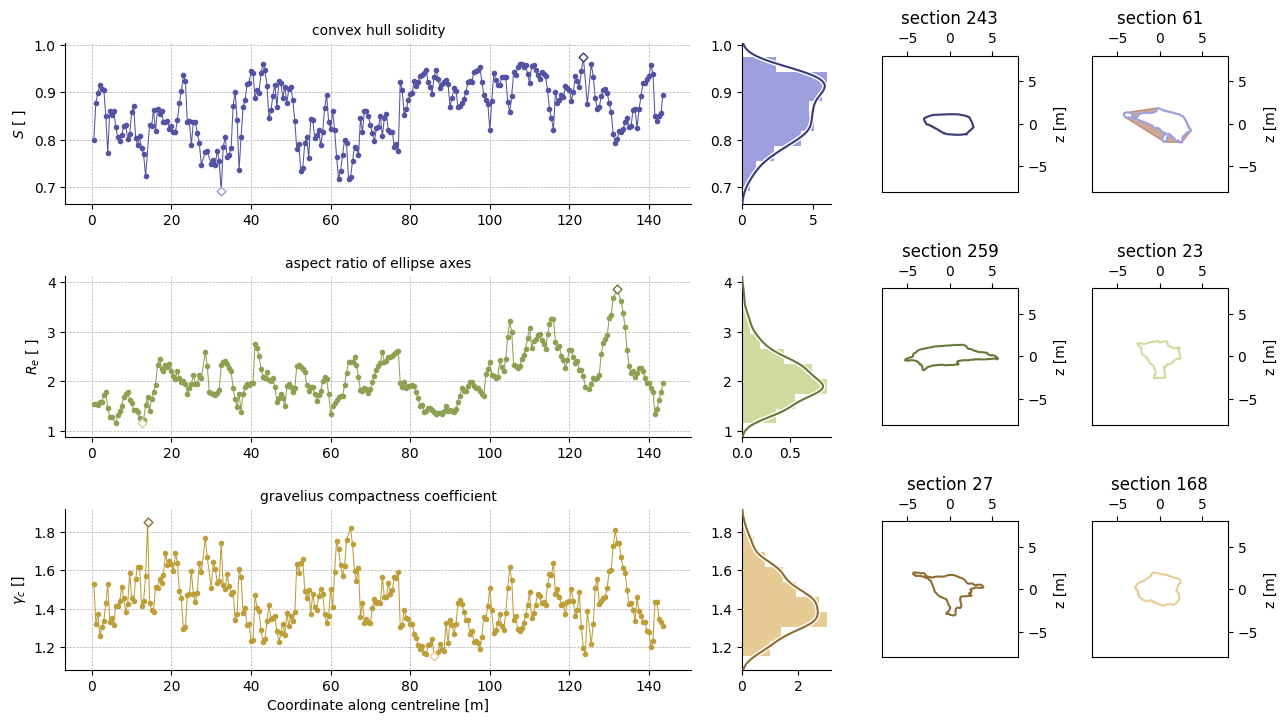

In [57]:
fig = plt.figure(figsize = (15, 3*n_attr))

gs = GridSpec(7*n_attr, 50)

labels = [geom.DESCRIPTOR_MAP[header[elem]]["name"] for elem in attributes]
units = [geom.DESCRIPTOR_MAP[header[elem]]["unit"] for elem in attributes]
abbrs = [geom.DESCRIPTOR_MAP[header[elem]]["abbr"] for elem in attributes]

descriptors = {}

for n, (col, label, unit, abbr) in enumerate(zip(attributes, labels, units, abbrs)):
    i = 7*n
    print(i)
    ax = fig.add_subplot(gs[i:i+5, :27])
    ax.set_ylabel(f"{abbr} [{unit}]")
    ax.set_title(label, fontsize =10)
    
    ax_hist = fig.add_subplot(gs[i:i+5, 29:33], sharey = ax)
    
    ax_inset1 = fig.add_subplot(gs[i:i+5, 35:41])
    ax_inset2 = fig.add_subplot(gs[i:i+5, 44:], sharex = ax_inset1, sharey = ax_inset1)
    
    last = False
    if n == len(attributes) -1:
        last = True
    
    plotDescriptor(sections2d, conduit_descriptors[~ignore_calc],header, col, ax, ax_hist, ax_inset1, ax_inset2, inset_size=INSET_SIZE, last = last, attr_n=n)

plt.savefig(f"./temp/barcelona_figures/curvilinear_attributes_{thecavepassage}_{'_'.join([str(elem) for elem in attributes])}.png")

In [58]:
attributes = [7, 8, 11]
n_attr = len(attributes)

0
286
7
286
14
286


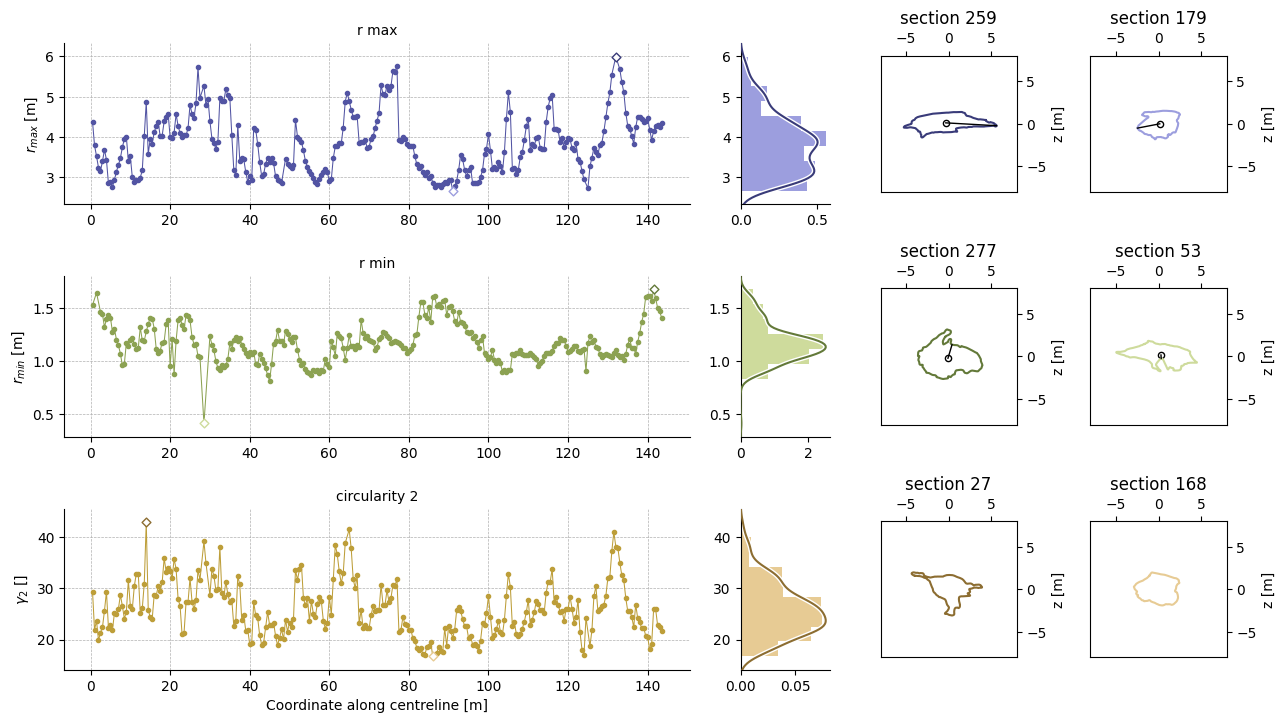

In [59]:
fig = plt.figure(figsize = (15, 3*n_attr))

gs = GridSpec(7*n_attr, 50)

labels = [geom.DESCRIPTOR_MAP[header[elem]]["name"] for elem in attributes]
units = [geom.DESCRIPTOR_MAP[header[elem]]["unit"] for elem in attributes]
abbrs = [geom.DESCRIPTOR_MAP[header[elem]]["abbr"] for elem in attributes]

descriptors = {}

for n, (col, label, unit, abbr) in enumerate(zip(attributes, labels, units, abbrs)):
    i = 7*n
    print(i)
    ax = fig.add_subplot(gs[i:i+5, :27])
    ax.set_ylabel(f"{abbr} [{unit}]")
    ax.set_title(label, fontsize =10)
    
    ax_hist = fig.add_subplot(gs[i:i+5, 29:33], sharey = ax)
    
    ax_inset1 = fig.add_subplot(gs[i:i+5, 35:41])
    ax_inset2 = fig.add_subplot(gs[i:i+5, 44:], sharex = ax_inset1, sharey = ax_inset1)
    
    last = False
    if n == len(attributes) -1:
        last = True
    
    plotDescriptor(sections2d, conduit_descriptors[~ignore_calc],header, col, ax, ax_hist, ax_inset1, ax_inset2, inset_size=INSET_SIZE, last = last, attr_n=n)

plt.savefig(f"./temp/barcelona_figures/curvilinear_attributes_{thecavepassage}_{'_'.join([str(elem) for elem in attributes])}.png")

In [ ]:
fig, axes = plt.subplots(3, 7, figsize = (10, 6))

for c, (descriptor, ax) in enumerate(zip(header[:-1], axes.flatten())):
    data = conduit_descriptors[:, c]
    

    too_small_areas = conduit_descriptors[:, 0] < 1

    bins = np.linspace(*np.quantile(data, [0.025, 0.975]), int(1+np.log2(len(data))))

    ax.hist(data[~too_small_areas], bins= bins, density=True)

    ax.set_xlim(*geom.DESCRIPTOR_MAP[descriptor]["bounds"])
    ax.set_ylabel("frequency density")
    ax.set_xlabel(f"{geom.DESCRIPTOR_MAP[descriptor]['abbr']} [{geom.DESCRIPTOR_MAP[descriptor]['unit']}]")
    ax.set_title(f"{geom.DESCRIPTOR_MAP[descriptor]['name']}", fontsize=6)

plt.tight_layout()
plt.savefig("./temp/barcelona_figures/{thecavepassage}_Histograms.png")
plt.show()

In [ ]:
centreline = np.loadtxt(centreline_filepaths[idx], skiprows=1)
interpolated_centreline, curvilinear_coords, normed_vectors = return_centreline_parametrisation(centreline)

In [ ]:
sections = [np.loadtxt(join(sections_directory, f"s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))]

In [ ]:
fill_curves = np.array([np.loadtxt(join(sections_directory, f"fill_curve_s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))])

In [ ]:
diameters_fill_curves = 4*fill_curves[:, 1:-1, 1] / fill_curves[:, 1:-1, 2]

In [ ]:
header

In [ ]:
fig, axes = plt.subplots(1, 3, figsize = (10, 5))

for fill_curve in fill_curves:
    diameters_fill_curve = 4*fill_curve[1:-1, 1] / fill_curve[1:-1, 2]

    axes[0].plot(*fill_curve[:-1, [0, 1]].T, color = "lightgrey", lw = 0.5)
    axes[1].plot(*fill_curve[:-1, [0, 2]].T, color = "lightgrey", lw = 0.5)
    axes[2].plot(fill_curve[1:-1, 0], diameters_fill_curve, color = "lightgrey", lw = 0.5)
    
    for q, color in zip((0.025, 0.5, 0.975), ("C1", "C0", "C1")):
        axes[0].plot(fill_curve[:-1, 0], np.quantile(fill_curves[:, :-1, 1],q,  axis =0), color = color, label = "")
        axes[1].plot(fill_curve[:-1, 0], np.quantile(fill_curves[:, :-1, 2],q,  axis =0), color = color)
        axes[2].plot(fill_curve[1:-1, 0], np.quantile(diameters_fill_curves, q, axis = 0), color = color)

axes[0].set_ylabel("section wetted area [m$^2$]")
axes[1].set_ylabel("section wetted perimeter [m]")
axes[2].set_ylabel("wet section\n hydraulic diameter [m]")

for ax in axes:
        ax.set_xlabel("fill fraction")

axes[1].set_title(f"summary filling up behaviour for {thecavepassage}")
plt.tight_layout()
plt.savefig("./temp/filling_up_curves.png")
plt.show()

In [ ]:
def equivalent_dh(dhi, li):
    # harmonic mean along the section 
    return np.sum(li)**(1/4) * np.sum(li *dhi**(-4))**(-1/4)

In [ ]:
li = np.diff(curvilinear_coords)

descriptor = "hydraulic_diameter"
col = np.argwhere(np.array(header) == descriptor)[0]
print(col)
dhi = conduit_descriptors[:, col].flatten()

descriptor = "max_chord_length"
col = np.argwhere(np.array(header) == descriptor)[0]
print(col)
max_chords = conduit_descriptors[:, col].flatten()

In [ ]:
plt.hist(dhi)

In [ ]:

fig, (ax, axchords) = plt.subplots(2, 1, figsize = (8, 5))

ax.plot(curvilinear_coords, dhi, "-o", markersize=3)


#plt.plot(curvilinear_coords[1:-1], [elem["hydraulic_diameter"] for elem in descriptors][1:], label = "hydraulic_diameter")
ax.axhline(equivalent_dh(dhi[1:], li), ls = "-", xmin=0.05, xmax=0.95)

ax.text(1,equivalent_dh(dhi[1:], li)*1.1, "eq. Dh section", color = "C0", fontsize = 8)

ax.set_xlabel("curvilinear coordinate [m]")
ax.set_ylabel("hydraulic diameter [m]")


axchords.plot(curvilinear_coords, max_chords, "-o", markersize=3)
axchords.set_xlabel("curvilinear coordinate [m]")
axchords.set_ylabel("longest chord [m]")

plt.tight_layout()
plt.savefig(f"./temp/test_hydraulic_diameters.png")